# Improved LiDAR Point Cloud Classification (v4 - Forb Re-added)

This notebook implements the improved workflow by combining 3D height data (`Z_norm`) with the 2D vegetation structure mask (`mask_structure_3072.109.tif`).

**This version (v4) maps pixels with value '0' (Unstructured) to Class 3 (Forb / Low Vegetation).**

**Workflow:**
1.  Load the original LAS file.
2.  Load the 2D `.tif` mask.
3.  Sample the 2D mask for every point's (X, Y) coordinate.
4.  Create a new classification:
    a.  Classify **Ground (Class 2)** using the `Z_norm` threshold.
    b.  Classify all **non-ground** points by mapping the 2D mask values to their correct classes, with '0' mapping to '3' (Forb).

## 1. Import Required Libraries

In [18]:
import laspy
import numpy as np
import rasterio
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt

print("✅ Libraries imported successfully (including rasterio)")

✅ Libraries imported successfully (including rasterio)


## 2. Define File Paths and Classification Scheme

This section contains the **v4 classification map**, re-adding Forb.

In [24]:
# --- Configuration ---
INPUT_LAS = "/media/laura/laura_usb/uas_data/DD0001/lidar/clipped/3d_structure/z_norm_csf_struct_tiles_multispectral.109.las"
MASK_TIF  = "/media/laura/laura_usb/uas_data/DD0001/imagery/inputs/masks/tiles_3072/raw/structure_class/annotation_raster/downsample_5cm_nearest/mask_structure_3072.109.tif"
GROUND_THRESHOLD = 0.05  # meters (|Z_norm| <= threshold → Ground)
# --- End Configuration ---

# Mask (pixel) → LAS (class) mapping: identity (mask already stores 64–68)
MASK_TO_LAS_MAP = {
    64: 64,  # Forb
    65: 65,  # Hummock
    66: 66,  # Shrub
    67: 67,  # Woody Debris
    68: 68,  # Mallee
}

# Labels for summaries/plots (keep 1/2 for Unclassified/Ground if you display them)
NEW_LABELS = {
    1:  "Unclassified (Other)",
    2:  "Ground",
    64: "Forb",
    65: "Hummock",
    66: "Shrub",
    67: "Woody Debris",
    68: "Mallee",
}

# If your TIFF lacks a nodata value, we’ll fall back to 255
MASK_NODATA_FALLBACK = 255

print("🔧 Classification scheme ready (identity mapping for 64–68).")

🔧 Classification scheme ready (identity mapping for 64–68).


## 3. Load LiDAR Data

In [25]:
las = laspy.read(INPUT_LAS)

# Extract coordinates and Z_norm
z_norm = np.array(las["Z_norm"], dtype=np.float32)
coords = np.vstack((las.x, las.y)).transpose()

print(f"📊 Loaded {len(las.points):,} points from LAS file.")
print(f"   Z_norm range: {z_norm.min():.3f}m to {z_norm.max():.3f}m")
print(f"🖌️ Sampling 2D mask '{MASK_TIF}' for {len(coords):,} points...")

📊 Loaded 1,594,668 points from LAS file.
   Z_norm range: 0.000m to 5.216m
🖌️ Sampling 2D mask '/media/laura/laura_usb/uas_data/DD0001/imagery/inputs/masks/tiles_3072/raw/structure_class/annotation_raster/downsample_5cm_nearest/mask_structure_3072.109.tif' for 1,594,668 points...


## 4. Load 2D Mask and Sample Point Values

In [27]:
with rasterio.open(MASK_TIF) as src:
    # Read nodata from the file (fallback to 255 if None)
    MASK_NODATA = src.nodata if src.nodata is not None else MASK_NODATA_FALLBACK
    sampled_values = np.array([val[0] for val in src.sample(coords)], dtype=np.int32)
    print(f"   Raster CRS: {src.crs}")
    print(f"   Raster bounds: {src.bounds}")
    print(f"   Raster nodata: {MASK_NODATA}")

print("✅ Sampling complete.")
print(f"   Found mask values: {np.unique(sampled_values)}")
print(f"   Mask value counts: {Counter(sampled_values)}")

   Raster CRS: EPSG:7854
   Raster bounds: BoundingBox(left=461771.56469617935, bottom=6237506.107523298, right=461802.26469617937, top=6237536.807523298)
   Raster nodata: 255.0
✅ Sampling complete.
   Found mask values: [ 65  66  67  68 255]
   Mask value counts: Counter({255: 1260515, 68: 309712, 66: 12095, 65: 9998, 67: 2348})


## 5. Create New Classification

1.  **Start** by setting all points to `Class 1` (Unclassified).
2.  **First Pass**: Classify **Ground (Class 2)** using `Z_norm`.
3.  **Second Pass**: Classify all **non-ground** points using the `sampled_values` from the mask.

In [28]:
print("🔧 Remapping LAS classifications...")

# 1️⃣ Initialize all points as Class 1 (Unclassified)
new_classification = np.ones(len(las.points), dtype=np.uint8)

# 2️⃣ Classify Ground Points (Class 2) — use absolute Z_norm
ground_mask = (np.abs(z_norm) <= GROUND_THRESHOLD)
new_classification[ground_mask] = 2
print(f"   • Found {ground_mask.sum():,} ground points (Class 2)")

# 3️⃣ Classify Non-Ground Points Using Mask 64–68 (ignore NoData + ground)
non_ground_mask = ~ground_mask
print(f"   • Classifying {non_ground_mask.sum():,} non-ground points based on mask...")

mapper = sampled_values.copy()
mapper[ground_mask] = -1
mapper[mapper == MASK_NODATA] = -1

# Optional: warn about codes not in 64–68 (and not -1)
valid_codes = np.array([64, 65, 66, 67, 68], dtype=np.int32)
unexpected = np.setdiff1d(np.unique(mapper[(mapper >= 0)]), valid_codes)
if unexpected.size:
    print(f"   ⚠️ Unexpected mask codes encountered (ignored): {unexpected}")

# Apply identity mapping 64–68 → 64–68
for mask_val, las_class in MASK_TO_LAS_MAP.items():
    idx = (mapper == mask_val)
    new_classification[idx] = las_class
    label = NEW_LABELS.get(las_class, "Unknown")
    print(f"     - Mask value '{mask_val}' → Class {las_class} ({label}) — {idx.sum():,} points")

print("✅ Classification remapping complete.")

🔧 Remapping LAS classifications...
   • Found 1,307,721 ground points (Class 2)
   • Classifying 286,947 non-ground points based on mask...
     - Mask value '64' → Class 64 (Forb) — 0 points
     - Mask value '65' → Class 65 (Hummock) — 2,562 points
     - Mask value '66' → Class 66 (Shrub) — 2,228 points
     - Mask value '67' → Class 67 (Woody Debris) — 1,214 points
     - Mask value '68' → Class 68 (Mallee) — 189,508 points
✅ Classification remapping complete.


## 6. Validate New Classification


📊 NEW Classification Distribution (v4 — 64–68):
  Class 1:     91,435 points ( 5.73%) - Unclassified (Other)
  Class 2:  1,307,721 points (82.01%) - Ground
  Class 65:      2,562 points ( 0.16%) - Hummock
  Class 66:      2,228 points ( 0.14%) - Shrub
  Class 67:      1,214 points ( 0.08%) - Woody Debris
  Class 68:    189,508 points (11.88%) - Mallee

  Total:     1,594,668 points


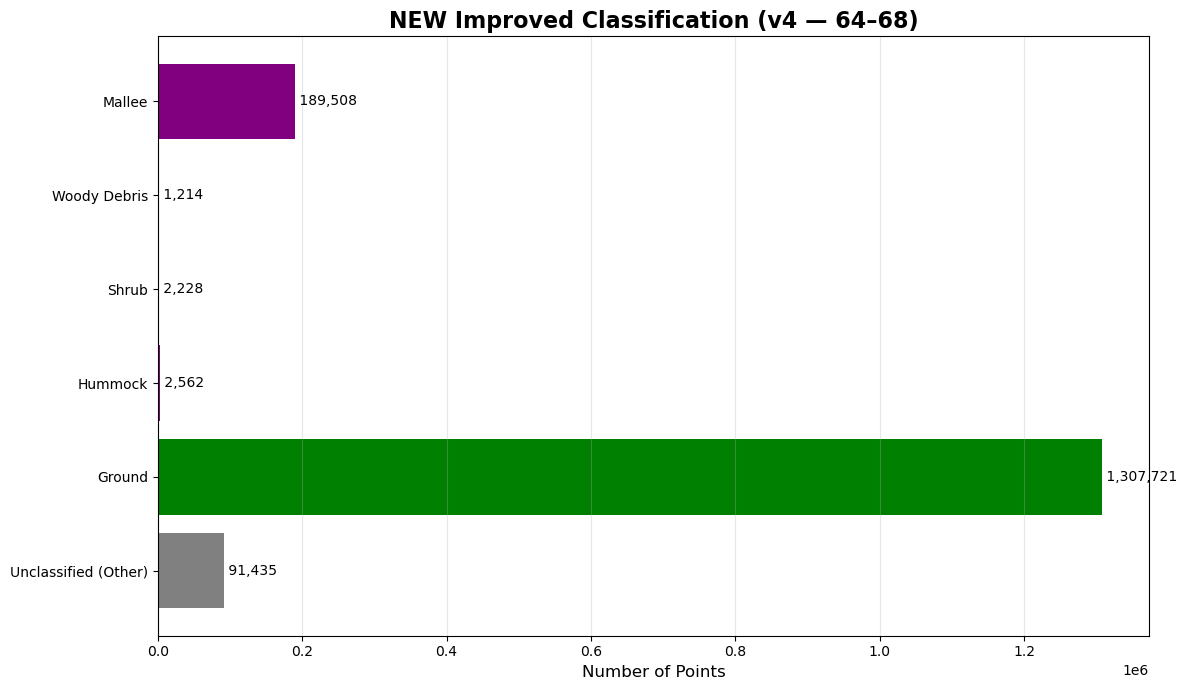

In [29]:
new_counts = Counter(new_classification)

print("\n" + "=" * 70)
print("📊 NEW Classification Distribution (v4 — 64–68):")
print("=" * 70)

total = len(new_classification)
for class_id in sorted(new_counts):
    label = NEW_LABELS.get(class_id, f"Unknown ({class_id})")
    count = new_counts[class_id]
    percentage = 100 * count / total
    print(f"  Class {class_id}: {count:>10,} points ({percentage:>5.2f}%) - {label}")

print(f"\n  Total:    {total:>10,} points")

# Plot with class-specific colors
fig, ax = plt.subplots(figsize=(12, 7))

ids = sorted(new_counts.keys())
new_plot_labels = [NEW_LABELS.get(c, f"Class {c}") for c in ids]
new_values = [new_counts[c] for c in ids]

def get_color(c):
    if c == 2: return 'green'        # Ground
    if c == 1: return 'gray'         # Unclassified
    if c in [4, 5]: return 'orange'  # Med/High Veg (legacy ASPRS)
    if c > 7: return 'purple'        # User Defined (64–68, etc.)
    return 'lightblue'               # Other

colors_new = [get_color(c) for c in ids]

ax.barh(new_plot_labels, new_values, color=colors_new)
ax.set_xlabel("Number of Points", fontsize=12)
ax.set_title("NEW Improved Classification (v4 — 64–68)", fontsize=16, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')
for i, v in enumerate(new_values):
    ax.text(v, i, f' {v:,}', va='center', fontsize=10)

plt.tight_layout()
plt.savefig("new_classification_chart_v4.png")
plt.show()

## 7. Export Corrected LAS File

In [30]:
input_path = Path(INPUT_LAS)
output_las = str(input_path.parent / (input_path.stem + "_mask_classified_v4.las"))

print(f"💾 Saving improved classification to:\n   {output_las}")

# Create new LAS file with improved classification
las_out = laspy.LasData(las.header)
las_out.points = las.points.copy()

# Apply new classification
las_out.classification = new_classification
las_out.header.software_id = "Mask-based Classification v4 (Laura)"

# Save
las_out.write(output_las)

print(f"\n✅ Successfully saved improved LAS file!")
print(f"\n📊 Final Statistics:")
for class_id in sorted(new_counts):
    label = NEW_LABELS.get(class_id, f"Unknown ({class_id})")
    print(f"   - {label} (Class {class_id}): {new_counts.get(class_id, 0):,}")

💾 Saving improved classification to:
   /media/laura/laura_usb/uas_data/DD0001/lidar/clipped/3d_structure/z_norm_csf_struct_tiles_multispectral.109_mask_classified_v4.las

✅ Successfully saved improved LAS file!

📊 Final Statistics:
   - Unclassified (Other) (Class 1): 91,435
   - Ground (Class 2): 1,307,721
   - Hummock (Class 65): 2,562
   - Shrub (Class 66): 2,228
   - Woody Debris (Class 67): 1,214
   - Mallee (Class 68): 189,508
